<a href="https://colab.research.google.com/github/sebaaceituno-afk/sic_ia_2026/blob/main/ejercicios_estudiantes/SIC2026_SOLO_GRUPO_1_RESUELTO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TRABAJO RESUELTO — GRUPO 1 (1A, 1B, 1C y 1D)

**Estado:** las explicaciones, los cuatro ejemplos de código, los cuatro ejercicios y sus verificaciones ya están desarrollados. Las respuestas de los ejercicios están incluidas para entregar al equipo; para una actividad en vivo, sustituyan la respuesta por `None` antes de entregarles el reto a sus compañeros.

**Para ejecutar:** `Entorno de ejecución → Ejecutar todas` en Colab o `Run All` en Jupyter. Los grupos 2 y 3 permanecen como plantillas originales porque no corresponden a la tarea de Grupo 1.

**Pendiente humano:** que los expositores lean y adapten el guion, agreguen sus nombres y suban el archivo al repositorio.


## Preparación del entorno

Ejecuten esta celda. Importa las librerías, define la función `revisar` (la misma de la Clase 2) y una función `cargar_csv` para los datos de reserva del capítulo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    """Imprime si un ejercicio está bien resuelto."""
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

URL_DATOS = "https://raw.githubusercontent.com/davidlealo/sic_ia_2026/main/datos/cap05/"

def cargar_csv(nombre):
    """Carga un CSV de reserva del capítulo 5: primero desde el repositorio y, si no está, desde los archivos subidos a Colab."""
    try:
        return pd.read_csv(URL_DATOS + nombre)
    except Exception:
        try:
            return pd.read_csv(nombre)
        except FileNotFoundError:
            print(f"No encontré {nombre}. Súbelo con el ícono de carpeta de la izquierda o con:")
            print("from google.colab import files; files.upload()")

print("Listo.")

Listo.


---
# Grupo 1. Fundamentos de machine learning con scikit-learn (láminas 14 a 194)

Esta es la Unidad 1 del capítulo y la base de todo lo que viene. Se divide en cuatro subgrupos:

| Subgrupo | Láminas | Tema |
|---|---|---|
| 1A | 14 a 47 | Parámetros e hiperparámetros, la API de scikit-learn |
| 1B | 48 a 112 | División de datos, sobreajuste, validación cruzada y preprocesamiento |
| 1C | 113 a 171 | Regularización y cómo encontrar el mejor modelo (caso iris) |
| 1D | 172 a 194 | Métricas de evaluación de clasificación |

## 1A · Parámetros, hiperparámetros y la API de scikit-learn
Alexandra,

**Láminas:** 14 a 47

**Conceptos que deben explicar:**

- Diferencia entre **parámetro** (lo aprende el modelo) e **hiperparámetro** (lo elige la persona).
- Qué es un **estimador**, un **clasificador** y un **regresor** en scikit-learn.
- Los tres métodos centrales: `fit`, `predict` y `transform`, y el atajo `fit_transform`.
- El flujo básico: cargar datos, dividir, crear el estimador, entrenar, predecir y evaluar.
- Principales módulos de scikit-learn (`datasets`, `model_selection`, `preprocessing`, `metrics`, etc.).

**Preguntas que la clase debe poder responder después de su presentación:**

1. En una regresión lineal, ¿la pendiente es un parámetro o un hiperparámetro? ¿Y el número de vecinos en KNN?
2. ¿Qué hace `fit` en un modelo y qué hace en un `StandardScaler`?
3. ¿Por qué el escalador se ajusta con los datos de entrenamiento y no con los de prueba?

**Material de reserva:** Láminas 21 a 45 y la sección 1.2 de `SIC_AI_Ch05_Unit01.ipynb` (carpeta *Data and IPYNB Files / Chapter 5*).

### Kit de inicio

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = load_wine(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Un transformador: fit aprende media y desviación; transform las aplica
escalador = StandardScaler().fit(X_tr)
X_tr_esc, X_te_esc = escalador.transform(X_tr), escalador.transform(X_te)
print("Media aprendida (primeras 3 columnas):", escalador.mean_[:3].round(2))

# Un estimador: n_neighbors es un hiperparámetro que elegimos nosotros
knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr_esc, y_tr)
print("Exactitud en prueba:", round(knn.score(X_te_esc, y_te), 3))

Media aprendida (primeras 3 columnas): [12.96  2.29  2.36]
Exactitud en prueba: 0.944


### Su explicación — guion de exposición (4–5 min)
**Idea central:** un algoritmo aprende reglas a partir de ejemplos. En regresión, la pendiente y el intercepto son **parámetros** calculados en `fit`; en KNN, el número de vecinos `n_neighbors` es un **hiperparámetro** definido antes de entrenar.

- Un **estimador** es un objeto de scikit-learn con método `fit`. Un **clasificador** predice categorías (tipo de vino); un **regresor** predice cantidades (precio, temperatura).
- `fit(X_train,y_train)` aprende de los datos; `predict(X_test)` devuelve predicciones. En un transformador, `fit` aprende estadísticas de entrenamiento, `transform` las aplica y `fit_transform` combina los dos pasos.
- Flujo correcto: **cargar → dividir → ajustar transformaciones SOLO en train → entrenar → predecir test → medir**. Nunca usar datos de prueba para estimar media/desviación, porque introduciría información ajena al entrenamiento (fuga de datos).
- Módulos: `datasets` (datos), `model_selection` (división y CV), `preprocessing` (escalado/codificación), `neighbors` o `linear_model` (algoritmos), `metrics` (evaluación), `pipeline` (secuencia sin fuga).

**Qué decir al mostrar el código (4–5 min):** "Entrenamos KNN con y sin estandarizar. KNN calcula distancias; una columna con números grandes puede dominar si no escalamos. Aquí comparamos la exactitud en el mismo conjunto de prueba". Después señalen `n_neighbors=5` como hiperparámetro y `coef_`/`intercept_` de una regresión como parámetros. **Cierre:** "Escalamos usando solo entrenamiento".

**Respuestas de repaso:** pendiente = parámetro; K = hiperparámetro. `fit` del estimador aprende el modelo; `fit` de `StandardScaler` aprende media y escala. El test es para evaluación imparcial, no para ajustar el escalador.

In [3]:
# EJEMPLO PROPIO 1A: ¿Por qué escalar cambia KNN? Dataset vino
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import accuracy_score
import numpy as np

X_1a, y_1a = load_wine(return_X_y=True)
xa_tr, xa_te, ya_tr, ya_te = train_test_split(X_1a, y_1a, test_size=.3, stratify=y_1a, random_state=42)
knn_bruto = KNeighborsClassifier(n_neighbors=5).fit(xa_tr, ya_tr)
knn_escalado = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(xa_tr, ya_tr)
acc_bruto = accuracy_score(ya_te, knn_bruto.predict(xa_te))
acc_escalado = accuracy_score(ya_te, knn_escalado.predict(xa_te))
print(f"KNN sin escala: {acc_bruto:.3f} | KNN con escala: {acc_escalado:.3f}")
print('Hiperparámetro elegido por nosotros: n_neighbors =', knn_bruto.n_neighbors)
# Contraste: regresión lineal aprende coeficientes a partir de datos
reg_demo = LinearRegression().fit(xa_tr[:, :2], xa_tr[:, 2])
print('Parámetros aprendidos (coef_, intercept_):', reg_demo.coef_.round(3), round(reg_demo.intercept_, 3))
print('El StandardScaler del pipeline se ajustó SOLAMENTE con los datos de entrenamiento.')

KNN sin escala: 0.722 | KNN con escala: 0.944
Hiperparámetro elegido por nosotros: n_neighbors = 5
Parámetros aprendidos (coef_, intercept_): [0.096 0.033] 1.038
El StandardScaler del pipeline se ajustó SOLAMENTE con los datos de entrenamiento.


### Ejercicio para la clase (1A) — 2 minutos
**Desafío:** cambia `n_neighbors` de KNN a **3**, entrena un pipeline que primero estandarice los datos (`StandardScaler`) y después use `KNeighborsClassifier`, con `xa_tr` y `ya_tr`. Guarda el pipeline entrenado en `respuesta_1a`. La revisión verifica el tipo de pipeline, el valor de `k` y que pueda predecir. **No ajustes el escalador con el conjunto de prueba.**

In [4]:
# Respuesta 1A: reemplacen None por su solución.
# Pista: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(...)
respuesta_1a = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)).fit(xa_tr, ya_tr)

In [5]:
from sklearn.pipeline import Pipeline
revisar(lambda: isinstance(respuesta_1a, Pipeline)
       and isinstance(respuesta_1a.steps[0][1], StandardScaler)
       and isinstance(respuesta_1a.steps[-1][1], KNeighborsClassifier)
       and respuesta_1a.steps[-1][1].n_neighbors == 3
       and len(respuesta_1a.predict(xa_te)) == len(ya_te),
       '¡Correcto! Pipeline entrenado con k=3.', 'Revisa el escalado, k=3 y el entrenamiento.')

¡Correcto! Pipeline entrenado con k=3.


## 1B · División de datos, sobreajuste, validación cruzada y preprocesamiento
Sebastian Escobar, Pablo zamorano

**Láminas:** 48 a 112

**Conceptos que deben explicar:**

- Por qué se dividen los datos en **entrenamiento y prueba**, y qué es la **generalización**.
- **Sobreajuste** y su relación con la flexibilidad del modelo.
- **Validación cruzada**: k-fold y dejar uno fuera (LOO).
- **Valores faltantes**: detectarlos, eliminar filas o columnas, e **imputar** con `SimpleImputer`.
- **Datos categóricos**: ordinales y nominales, codificación de etiquetas y **one-hot** (`get_dummies`, `OneHotEncoder`).
- **Escalado** de características: normalización (MinMax) y estandarización.

**Preguntas que la clase debe poder responder después de su presentación:**

1. ¿Por qué evaluar con los mismos datos de entrenamiento da una nota engañosa?
2. ¿Qué ventaja tiene la validación cruzada de 5 pliegues frente a una sola división?
3. ¿Cuándo conviene codificar una variable con números enteros y cuándo con one-hot?
4. ¿Qué diferencia hay entre `MinMaxScaler` y `StandardScaler`?

**Material de reserva:** Sección 1.4 de `SIC_AI_Ch05_Unit01.ipynb`; `data_titanic.csv` tiene faltantes reales para practicar.

### Kit de inicio

In [6]:
# KIT DE INICIO 1B (sin internet): faltantes, categorías, escalado y validación cruzada
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier

vino = load_wine(as_frame=True)
df_demo = vino.frame.copy()
df_demo.loc[df_demo.index[::17], 'alcohol'] = np.nan  # Faltantes de ejemplo, creados intencionalmente
print('Faltantes en alcohol:', df_demo['alcohol'].isna().sum())
print('Imputación (3 primeras filas):', SimpleImputer(strategy='median').fit_transform(df_demo[['alcohol']])[:3].ravel())
print('One-hot (ejemplo):', pd.get_dummies(pd.Series(['norte','sur','norte']), dtype=int).to_numpy())
print('MinMax:', MinMaxScaler().fit_transform(vino.data[['alcohol']])[:3].ravel().round(2))
print('Standard:', StandardScaler().fit_transform(vino.data[['alcohol']])[:3].ravel().round(2))
cv_demo = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
resultados_demo = cross_val_score(DecisionTreeClassifier(random_state=42), vino.data, vino.target, cv=cv_demo)
print('Exactitud CV 5 pliegues:', resultados_demo.round(3), 'media:', resultados_demo.mean().round(3))

Faltantes en alcohol: 11
Imputación (3 primeras filas): [13.05 13.2  13.16]
One-hot (ejemplo): [[1 0]
 [0 1]
 [1 0]]
MinMax: [0.84 0.57 0.56]
Standard: [1.52 0.25 0.2 ]
Exactitud CV 5 pliegues: [0.889 0.917 0.889 0.829 0.943] media: 0.893


### Su explicación — guion de exposición (4–5 min)
**Idea central:** la exactitud en entrenamiento no demuestra que un modelo vaya a funcionar con casos nuevos.

- **Entrenamiento** ajusta el modelo; **prueba** estima el rendimiento en datos no vistos. **Sobreajuste**: memoriza detalles o ruido, rinde mucho mejor en train que en test; **subajuste**: modelo demasiado simple, ambos rendimientos bajos.
- **Validación cruzada k-fold:** divide en k pliegues; usa k−1 para entrenar y 1 para validar, rotando. **LOO** deja un solo registro fuera en cada iteración: permite usar muchos ejemplos para entrenar, pero cuesta más computacionalmente.
- **Faltantes:** primero inspeccionar con `isna().sum()`. Eliminar registros puede perder información; imputar con mediana sirve para números y es robusto ante extremos. Ajustar imputación solamente sobre train.
- **Categóricas:** ordinal = orden natural (bajo/medio/alto); nominal = sin orden (isla, comuna). One-hot crea columnas indicadoras y evita inventar un orden inexistente. `get_dummies` es útil para exploración; `OneHotEncoder` dentro de un pipeline permite transformar datos nuevos consistentemente.
- **MinMaxScaler** reescala al intervalo [0,1] estimado en train (datos nuevos podrían excederlo). **StandardScaler** resta media y divide por desviación típica de train (valor 0 = media).

**Qué decir al mostrar el código (4–5 min):** "Mismo dataset, árboles de distinta complejidad. Si el árbol sin límite logra gran exactitud entrenando, pero baja en prueba, vemos sobreajuste. Después medimos KNN con 5 pliegues y escalado dentro de un pipeline, evitando fuga entre pliegues".

**Respuestas de repaso:** evaluar en train es optimista; CV evalúa en múltiples separaciones; números ordinales solo para categorías ordenadas; MinMax usa rango, Standard usa media y desviación.

In [7]:
# EJEMPLO PROPIO 1B: sobreajuste y fuga de información
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X_1b, y_1b = load_wine(return_X_y=True)
xb_tr, xb_te, yb_tr, yb_te = train_test_split(X_1b, y_1b, test_size=.30, random_state=19, stratify=y_1b)
for profundidad in [2, None]:
    arbol = DecisionTreeClassifier(max_depth=profundidad, random_state=19).fit(xb_tr, yb_tr)
    print('Profundidad:', profundidad, '| entrenamiento:', round(arbol.score(xb_tr, yb_tr), 3), '| prueba:', round(arbol.score(xb_te, yb_te), 3))
# El escalado está dentro del pipeline para ajustarse en cada pliegue de entrenamiento
modelo_cv_1b = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
cv_1b = StratifiedKFold(n_splits=5, shuffle=True, random_state=19)
puntuaciones_1b = cross_val_score(modelo_cv_1b, X_1b, y_1b, cv=cv_1b)
print('Puntajes de 5 pliegues:', puntuaciones_1b.round(3), '| promedio:', round(puntuaciones_1b.mean(), 3))

Profundidad: 2 | entrenamiento: 0.96 | prueba: 0.889
Profundidad: None | entrenamiento: 1.0 | prueba: 0.944
Puntajes de 5 pliegues: [1.    0.972 0.972 0.971 0.971] | promedio: 0.977


### Ejercicio para la clase (1B) — 2 minutos
**Desafío:** crea una **validación cruzada estratificada de 5 pliegues** con mezcla (`shuffle=True`) y semilla `19`. Guarda el objeto en `respuesta_1b`. ¿Por qué es preferible validar en varios pliegues en lugar de medir sobre los datos de entrenamiento?

In [8]:
# Respuesta 1B
respuesta_1b = StratifiedKFold(n_splits=5, shuffle=True, random_state=19)

In [9]:
revisar(lambda: isinstance(respuesta_1b, StratifiedKFold)
       and respuesta_1b.n_splits == 5 and respuesta_1b.shuffle
       and respuesta_1b.random_state == 19
       and len(list(respuesta_1b.split(X_1b, y_1b))) == 5,
       '¡Correcto! Validación cruzada estratificada de 5 pliegues.', 'Revisa n_splits=5, shuffle=True y random_state=19.')

¡Correcto! Validación cruzada estratificada de 5 pliegues.


## 1C · Regularización y búsqueda del mejor modelo


**Láminas:** 113 a 171

**Conceptos que deben explicar:**

- **Compensación sesgo-varianza** y cómo la **regularización** limita la complejidad del modelo.
- Diferencia entre **Ridge** (L2), **Lasso** (L1) y **Elastic Net**.
- El proceso completo con el caso **iris**: entender los datos, EDA, correlaciones, proporción de clases.
- **Selección de algoritmo** y estrategia de generalización: validación cruzada y **validación estratificada**.
- **Curva de aprendizaje**: qué dice sobre si conviene conseguir más datos.
- **Búsqueda de hiperparámetros** con `GridSearchCV`.

**Preguntas que la clase debe poder responder después de su presentación:**

1. ¿Por qué Lasso puede dejar coeficientes exactamente en cero y Ridge no?
2. ¿Qué indica una curva de aprendizaje donde entrenamiento y validación siguen separados?
3. Si `GridSearchCV` prueba 3 valores de un hiperparámetro y 4 de otro con 5 pliegues, ¿cuántos modelos entrena?

**Material de reserva:** Sección 1.5 de `SIC_AI_Ch05_Unit01.ipynb` y `data_Iris.csv`; `ex_0306.ipynb` con `data_mtcars.csv` para Ridge y Lasso.

### Kit de inicio

alpha=0.01: Ridge ceros=0, Lasso ceros=0
alpha=0.1: Ridge ceros=0, Lasso ceros=3
alpha=1: Ridge ceros=0, Lasso ceros=7
Mejores hiperparámetros: {'svc__C': 10, 'svc__gamma': 'scale'} | exactitud CV: 0.989


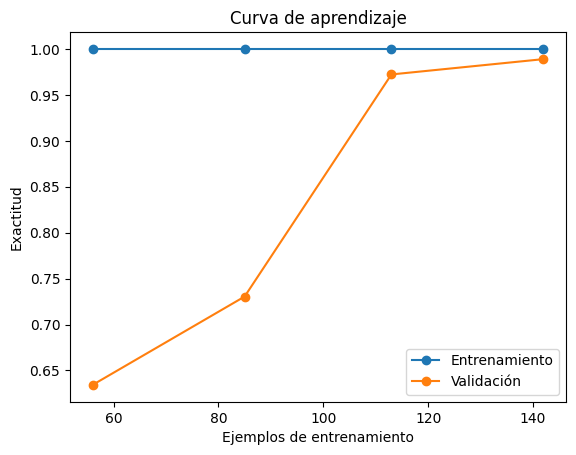

In [10]:
from sklearn.datasets import load_diabetes, load_wine
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV, learning_curve, StratifiedKFold
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Regularización: cuántos coeficientes quedan en cero al aumentar alpha
Xd, yd = load_diabetes(return_X_y=True)
for a in [0.01, 0.1, 1]:
    print(f"alpha={a}: Ridge ceros={np.sum(Ridge(alpha=a).fit(Xd, yd).coef_ == 0)}, "
          f"Lasso ceros={np.sum(Lasso(alpha=a).fit(Xd, yd).coef_ == 0)}")

# Búsqueda de hiperparámetros con validación estratificada
Xw, yw = load_wine(return_X_y=True)
grilla = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                      {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.1, 0.01, 0.001]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=0))
grilla.fit(Xw, yw)
print("Mejores hiperparámetros:", grilla.best_params_, "| exactitud CV:", round(grilla.best_score_, 3))

# Curva de aprendizaje
tam, tr, va = learning_curve(grilla.best_estimator_, Xw, yw, cv=5, train_sizes=np.linspace(0.2, 1, 5))
plt.plot(tam, tr.mean(axis=1), marker="o", label="Entrenamiento")
plt.plot(tam, va.mean(axis=1), marker="o", label="Validación")
plt.xlabel("Ejemplos de entrenamiento"); plt.ylabel("Exactitud"); plt.legend(); plt.title("Curva de aprendizaje"); plt.show()

### Su explicación — guion de exposición (4–5 min)
**Idea central:** buscamos equilibrio entre un modelo flexible y uno que generaliza a datos nuevos.

- **Sesgo-varianza:** modelos demasiado rígidos tienden al subajuste (sesgo alto); excesivamente flexibles pueden variar mucho con los datos (varianza alta).
- **Regularización:** penaliza coeficientes grandes. **Ridge (L2)** los reduce de forma continua; **Lasso (L1)** puede llevar algunos exactamente a cero y actuar como selector de variables; **Elastic Net** combina L1 y L2.
- **EDA de Iris:** revisar cantidad de registros, variables, distribución de clases, promedios y correlaciones antes de modelar. Tener un test reservado desde el inicio.
- **Validación estratificada:** mantiene aproximadamente la proporción de clases en los pliegues. `GridSearchCV` prueba combinaciones de hiperparámetros con CV sobre train; luego evaluamos la mejor opción una sola vez en test.
- **Curva de aprendizaje:** compara errores/puntajes de entrenamiento y validación para tamaños de train crecientes. Una brecha persistente sugiere alta varianza; si ambos puntajes son bajos y juntos, suele haber subajuste. Más datos pueden ayudar, pero no siempre.

**Qué decir al mostrar el código (4–5 min):** "Mostramos cómo Ridge y Lasso cambian al aumentar alpha. Luego usamos Iris, revisamos correlaciones y comparamos C y gamma de SVC con validación estratificada. El conjunto de prueba se evalúa recién al final".

**Respuestas de repaso:** Lasso aplica penalización L1, que puede producir ceros exactos; una brecha que persiste indica varianza; 3 × 4 × 5 = **60 ajustes de CV** (más reajuste final por defecto).

In [11]:
# EJEMPLO PROPIO 1C: camino de regularización + GridSearchCV con evaluación separada
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.svm import SVC

Xd_1c, yd_1c = load_diabetes(return_X_y=True)
alphas_1c = [0.01, 0.1, 1, 10]
for a in alphas_1c:
    ridge = Ridge(alpha=a).fit(Xd_1c, yd_1c)
    lasso = Lasso(alpha=a, max_iter=20000).fit(Xd_1c, yd_1c)
    print(f'alpha={a:>5}: norma Ridge={np.linalg.norm(ridge.coef_):.2f}, variables eliminadas Lasso={np.sum(np.isclose(lasso.coef_,0))}')

iris_1c = load_iris(as_frame=True)
print('Clases de iris:', iris_1c.target.value_counts().sort_index().to_dict())
print('Correlaciones (4 primeras variables):')
print(iris_1c.data.corr().round(2))
Xc_tr, Xc_te, yc_tr, yc_te = train_test_split(iris_1c.data, iris_1c.target, test_size=.25, stratify=iris_1c.target, random_state=24)
cv_1c = StratifiedKFold(n_splits=5, shuffle=True, random_state=24)
busqueda_1c = GridSearchCV(make_pipeline(StandardScaler(), SVC()), {'svc__C':[0.1,1,10], 'svc__gamma':['scale', 0.1, 0.01, 0.001]}, cv=cv_1c)
busqueda_1c.fit(Xc_tr, yc_tr)
print('Combinaciones:', len(busqueda_1c.cv_results_['params']), '| ajustes CV:', len(busqueda_1c.cv_results_['params'])*5)
print('Mejor configuración:', busqueda_1c.best_params_, '| CV:', round(busqueda_1c.best_score_,3), '| prueba final:', round(busqueda_1c.score(Xc_te,yc_te),3))

alpha= 0.01: norma Ridge=987.63, variables eliminadas Lasso=0
alpha=  0.1: norma Ridge=799.54, variables eliminadas Lasso=3
alpha=    1: norma Ridge=511.60, variables eliminadas Lasso=7
alpha=   10: norma Ridge=145.48, variables eliminadas Lasso=10
Clases de iris: {0: 50, 1: 50, 2: 50}
Correlaciones (4 primeras variables):
                   sepal length (cm)  sepal width (cm)  petal length (cm)  \
sepal length (cm)               1.00             -0.12               0.87   
sepal width (cm)               -0.12              1.00              -0.43   
petal length (cm)               0.87             -0.43               1.00   
petal width (cm)                0.82             -0.37               0.96   

                   petal width (cm)  
sepal length (cm)              0.82  
sepal width (cm)              -0.37  
petal length (cm)              0.96  
petal width (cm)               1.00  
Combinaciones: 12 | ajustes CV: 60
Mejor configuración: {'svc__C': 1, 'svc__gamma': 'scale'} | CV: 

### Ejercicio para la clase (1C) — 2 minutos
**Desafío:** una grilla con `C = [0.1, 1, 10]` y `gamma = ['scale', 0.1, 0.01, 0.001]` usa validación de **5 pliegues**. ¿Cuántos ajustes de modelo se realizan solo para la validación cruzada? Guarda el entero en `respuesta_1c`. *Pista: opciones de C × opciones de gamma × pliegues.*

In [12]:
# Respuesta 1C
respuesta_1c = 3 * 4 * 5

In [13]:
revisar(lambda: isinstance(respuesta_1c, (int, np.integer)) and respuesta_1c == 60,
       '¡Correcto! Se entrenan 60 modelos durante CV (más el reajuste final si refit=True).', 'Multiplica 3 x 4 x 5.')

¡Correcto! Se entrenan 60 modelos durante CV (más el reajuste final si refit=True).


## 1D · Métricas de evaluación de clasificación
Sebastian Aceituno

**Láminas:** 172 a 194

**Conceptos que deben explicar:**

- **Matriz de confusión**: verdaderos y falsos positivos y negativos, y su versión multiclase.
- **Precision, recall, fall-out y F1**: qué mide cada una y cuándo importa más.
- **Exactitud** y por qué no basta cuando las clases están desbalanceadas.
- `classification_report`.
- **Curva ROC** y **AUC**.
- Qué hacer si el rendimiento es malo: volver a pasos anteriores.

**Preguntas que la clase debe poder responder después de su presentación:**

1. En un test de una enfermedad grave, ¿qué es peor: un falso positivo o un falso negativo? ¿Qué métrica priorizarían?
2. Un modelo acierta 95% en un dataset donde 95% de los casos son negativos. ¿Es un buen modelo?
3. ¿Qué significa un AUC de 0,5?

**Material de reserva:** Láminas 172 a 194 y el final de la sección 1.5 de `SIC_AI_Ch05_Unit01.ipynb`.

### Kit de inicio

Matriz de confusión:
 [[ 58   6]
 [  6 101]]
Exactitud 0.930 | Precision 0.944 | Recall 0.944 | F1 0.944
              precision    recall  f1-score   support

     maligno       0.91      0.91      0.91        64
     benigno       0.94      0.94      0.94       107

    accuracy                           0.93       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.93      0.93      0.93       171



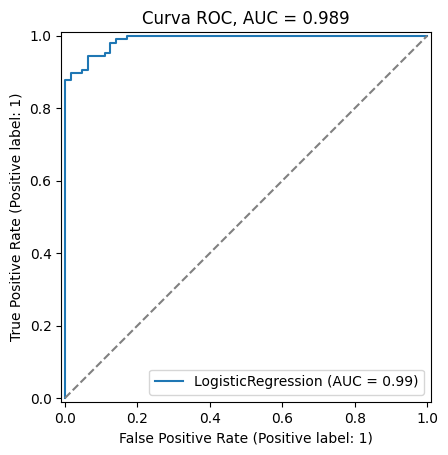

In [14]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, classification_report, RocCurveDisplay, roc_auc_score)

Xb, yb = load_breast_cancer(return_X_y=True)   # 1 = benigno, 0 = maligno
X_tr, X_te, y_tr, y_te = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)
modelo = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
pred = modelo.predict(X_te)

print("Matriz de confusión:\n", confusion_matrix(y_te, pred))
print(f"Exactitud {accuracy_score(y_te, pred):.3f} | Precision {precision_score(y_te, pred):.3f} | "
      f"Recall {recall_score(y_te, pred):.3f} | F1 {f1_score(y_te, pred):.3f}")
print(classification_report(y_te, pred, target_names=["maligno", "benigno"]))

RocCurveDisplay.from_estimator(modelo, X_te, y_te)
plt.plot([0, 1], [0, 1], "--", color="gray"); plt.title(f"Curva ROC, AUC = {roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1]):.3f}"); plt.show()

### Su explicación — guion de exposición (4–5 min)
**Idea central:** una sola cifra de exactitud puede ocultar errores relevantes, especialmente cuando hay pocos casos positivos.

- **Matriz de confusión:** TP = positivo correctamente detectado; TN = negativo correcto; FP = falsa alarma; FN = positivo que no detectamos.
- **Accuracy** = (TP+TN)/total. **Precision** = TP/(TP+FP): de lo marcado positivo, cuántos sí lo eran. **Recall/sensibilidad** = TP/(TP+FN): de los positivos reales, cuántos detectamos. **Fall-out/FPR** = FP/(FP+TN). **F1** combina precision y recall mediante media armónica.
- **`classification_report`** muestra precision, recall, F1 y soporte por clase. En multiclase, la matriz y las métricas se calculan por cada categoría, y `macro`/`weighted` ofrecen agregaciones distintas.
- **ROC:** grafica TPR frente a FPR a distintos umbrales. **AUC** resume separación: 0,5 ≈ azar; 1,0 = separación perfecta en los datos evaluados.
- Si el resultado es deficiente: revisar calidad de datos y etiquetas, balance de clases, preprocesamiento, modelo, hiperparámetros y umbral. Un falso negativo puede ser especialmente importante en detección de una enfermedad grave, pero depende de los costos reales y del contexto clínico.

**Qué decir al mostrar el código (4–5 min):** "En 100 registros, 95 son negativos. El modelo que siempre predice negativo alcanza 95% accuracy, pero recall cero. Por eso necesitamos mirar la matriz y F1. Luego comparamos con un ejemplo de puntajes probabilísticos ilustrativos y una ROC".

**Respuestas de repaso:** en detección temprana suele priorizarse recall para reducir falsos negativos, con consideración de falsos positivos; 95% accuracy no basta sin conocer la matriz; AUC 0,5 significa discriminación equivalente a azar en promedio.

Modelo que siempre dice "no":
Matriz [[TN,FP],[FN,TP]]:
 [[95  0]
 [ 5  0]]
Accuracy: 0.95 | Recall clase positiva: 0.0 | F1: 0.0
Modelo alternativo:
              precision    recall  f1-score   support

           0       0.98      0.91      0.94        95
           1       0.25      0.60      0.35         5

    accuracy                           0.89       100
   macro avg       0.61      0.75      0.65       100
weighted avg       0.94      0.89      0.91       100

AUC modelo alternativo: 0.851


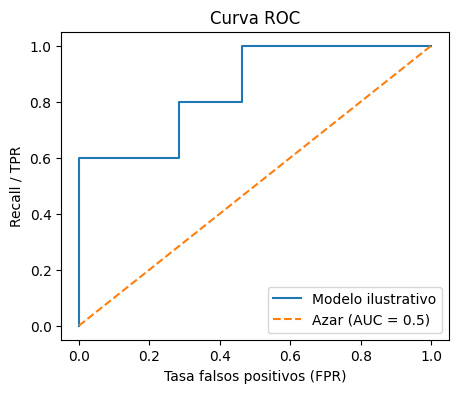

In [15]:
# EJEMPLO PROPIO 1D: cuando accuracy engaña por desbalance de clases
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

y_1d = np.array([0]*95 + [1]*5)  # 1 = casos minoritarios que queremos detectar
pred_mayoria_1d = np.zeros_like(y_1d)
print('Modelo que siempre dice "no":')
print('Matriz [[TN,FP],[FN,TP]]:\n', confusion_matrix(y_1d, pred_mayoria_1d))
print('Accuracy:', accuracy_score(y_1d,pred_mayoria_1d), '| Recall clase positiva:', recall_score(y_1d,pred_mayoria_1d,zero_division=0), '| F1:', f1_score(y_1d,pred_mayoria_1d,zero_division=0))
# Otro clasificador de demostración: probabilidades construidas para ilustrar ROC, no datos reales
p_1d = np.r_[np.linspace(.01,.55,95), np.array([.80,.70,.65,.40,.30])]
pred_1d = (p_1d >= .50).astype(int)
print('Modelo alternativo:')
print(classification_report(y_1d,pred_1d,zero_division=0))
print('AUC modelo alternativo:', round(roc_auc_score(y_1d,p_1d),3))
fpr_1d,tpr_1d,_ = roc_curve(y_1d,p_1d)
plt.figure(figsize=(5,4)); plt.plot(fpr_1d,tpr_1d,label='Modelo ilustrativo'); plt.plot([0,1],[0,1],'--',label='Azar (AUC = 0.5)');plt.xlabel('Tasa falsos positivos (FPR)');plt.ylabel('Recall / TPR');plt.title('Curva ROC');plt.legend();plt.show()

### Ejercicio para la clase (1D) — 2 minutos
**Desafío:** en una prueba hay 10 positivos reales. El modelo identifica correctamente **8**, pero deja escapar **2**. Calcula el **recall** (sensibilidad) y guarda el resultado decimal en `respuesta_1d`. *Fórmula: TP / (TP + FN).*

In [16]:
# Respuesta 1D
respuesta_1d = 8 / (8 + 2)

In [17]:
revisar(lambda: isinstance(respuesta_1d,(int,float,np.number)) and abs(float(respuesta_1d)-0.8)<1e-9,
       '¡Correcto! Recall = 0.8 (80%).','Recuerda: recall = TP / (TP + FN).')

¡Correcto! Recall = 0.8 (80%).
